# 30 — Les groupes abéliens finis : forme canonique, morphismes et automorphismes

**Navigation :** Index (README.md) | Précédent : 20-sylow-p-sous-groupes

**Thème.** Le carnet 20 a rendu calculables les théorèmes de Sylow, c'est-à-dire la
structure des groupes finis **quand on les voit par leurs sous-groupes**. Ce carnet prend
l'autre angle : la structure des groupes abéliens finis **quand on les voit par leur loi
de groupe**. Le résultat central est le théorème de classification : tout groupe abélien
fini s'écrit de façon unique comme produit de groupes cycliques, avec des ordres qui se
divisent les uns les autres (les *facteurs invariants*). Nous allons **calculer** cette
forme canonique, **compter** les groupes abéliens d'un ordre donné, **compter** les
morphismes et les automorphismes, et **mesurer** ce que le théorème ne dit pas : à quel
point la structure compte, et pas seulement l'ordre.

**Outil.** Python stdlib pur (`math.gcd`, `itertools`) plus `matplotlib` pour une figure —
la convention de la série (voir [README](README.md)). Les groupes abéliens sont représentés
par leurs facteurs invariants ; aucune dépendance externe n'est nécessaire.

**Ce que le carnet ne fait pas.** Il ne produit **aucune preuve** : ce sont des mesures sur
des groupes finis, obtenues par énumération exhaustive. Le versant formel (Mathlib) n'est
pas produit ici ; le carnet 08 montre comment la série articule les deux versants.

## 1. Une machine : un groupe abélien sous forme canonique

On représente un groupe abélien fini $G$ par la suite de ses **facteurs invariants**
$(n_1, n_2, \dots, n_r)$ avec $n_1 \mid n_2 \mid \dots \mid n_r$, c'est-à-dire
$G \simeq \mathbb{Z}/n_1\mathbb{Z} \times \cdots \times \mathbb{Z}/n_r\mathbb{Z}$. Un élément
est un tuple, l'addition est composante par composante (modulo $n_i$).

In [1]:
from math import gcd
from itertools import product


class GroupeAbelien:
    """Groupe abélien fini, sous forme canonique (facteurs invariants n_1 | n_2 | ... | n_r).

    Un élément est un tuple d'entiers modulo n_i ; l'addition est composante par
    composante. Le mot « canonique » annonce ce que le §2 mesurera : deux groupes
    abéliens isomorphes ont les mêmes facteurs invariants.
    """

    def __init__(self, invariants):
        self.invariants = tuple(int(n) for n in invariants)
        self.rang = len(self.invariants)

    @property
    def ordre(self):
        o = 1
        for n in self.invariants:
            o *= n
        return o

    def elements(self):
        """Tous les éléments du groupe, sous forme de tuples."""
        return list(product(*(range(n) for n in self.invariants)))

    def __repr__(self):
        if not self.invariants:
            return "groupe trivial"
        return " x ".join(f"Z/{n}Z" for n in self.invariants)


def addition(G, a, b):
    """Somme de deux éléments de G, composante par composante."""
    return tuple((x + y) % n for x, y, n in zip(a, b, G.invariants))


def soustraction(G, a, b):
    """Différence de deux éléments de G."""
    return tuple((x - y) % n for x, y, n in zip(a, b, G.invariants))


def neutre(G):
    """L'élément neutre de G."""
    return tuple(0 for _ in G.invariants)


C4 = GroupeAbelien((4,))
V4 = GroupeAbelien((2, 2))

print("C4 =", C4, "| ordre", C4.ordre)
print("     éléments :", C4.elements())
print("V4 =", V4, "| ordre", V4.ordre)
print("     éléments :", V4.elements())

C4 = Z/4Z | ordre 4
     éléments : [(0,), (1,), (2,), (3,)]
V4 = Z/2Z x Z/2Z | ordre 4
     éléments : [(0, 0), (0, 1), (1, 0), (1, 1)]


### Lecture : deux groupes de même ordre, deux machines différentes

$|C_4| = |V_4| = 4$, mais les deux groupes ne se ressemblent pas : $C_4$ a un élément
d'ordre $4$, $V_4$ n'a que des éléments d'ordre $2$. La suite des facteurs invariants
$(4)$ et $(2, 2)$ ne peut pas ignorer la différence : **elle la contient**. Toute la
suite du carnet repose sur ce fait — mesurer une structure, c'est d'abord la distinguer.

## 2. La classification : combien de groupes abéliens d'ordre $N$ ?

Le théorème dit qu'un groupe abélien fini d'ordre $N$ est déterminé par ses **diviseurs
élémentaires** : pour chaque nombre premier $p \mid N$, la composante $p$-primaire est
déterminée par une **partition** de l'exposant de $p$ dans $N$. Les facteurs invariants
s'obtiennent en alignant les exposants « par la droite » — le plus grand exposant dans le
dernier facteur — puis en multipliant colonne par colonne.

In [2]:
def factorisation(n):
    """Décomposition de n en facteurs premiers : {p: exposant}."""
    facteurs = {}
    d = 2
    while d * d <= n:
        while n % d == 0:
            facteurs[d] = facteurs.get(d, 0) + 1
            n //= d
        d += 1
    if n > 1:
        facteurs[n] = facteurs.get(n, 0) + 1
    return facteurs


def partitions(n, max_part=None):
    """Partitions de n en parts décroissantes (liste de tuples)."""
    if n == 0:
        return [()]
    if max_part is None or max_part > n:
        max_part = n
    resultat = []
    for k in range(max_part, 0, -1):
        for reste in partitions(n - k, k):
            resultat.append((k,) + reste)
    return resultat


def groupes_abeliens(N):
    """Tous les groupes abéliens d'ordre N, sous forme canonique.

    Pour chaque premier p | N, le p-groupe est déterminé par une partition de
    l'exposant de p. Les facteurs invariants s'obtiennent en alignant les exposants
    par la droite (le plus grand exposant dans le dernier facteur), puis en
    multipliant colonne par colonne : n_1 | n_2 | ... | n_r.
    """
    facteurs = factorisation(N)
    premiers = sorted(facteurs)
    par_premier = [partitions(facteurs[p]) for p in premiers]
    largeur = max(len(p) for p in par_premier) if par_premier else 0
    groupes = []
    for combinaison in product(*par_premier):
        # Alignement des exposants par la DROITE : le plus grand exposant dans le
        # DERNIER facteur, pour que n_1 | n_2 | ... | n_r (forme canonique).
        # `partitions` rend des parts decroissantes : chaque tuple est inverse.
        colonnes = [(0,) * (largeur - len(c)) + tuple(reversed(c)) for c in combinaison]
        invariants = []
        for j in range(largeur):
            v = 1
            for i, p in enumerate(premiers):
                v *= p ** colonnes[i][j]
            invariants.append(v)
        invariants = [v for v in invariants if v > 1]
        groupes.append(GroupeAbelien(invariants))
    return groupes


def nombre_attendu(N):
    """Nombre de groupes abéliens d'ordre N par la formule prod p(a_p).

    Chemin indépendant de l'énumération : pour chaque premier p | N, la
    composante p-primaire est déterminée par une partition de l'exposant a_p,
    donc le nombre de groupes est le produit des nombres de partitions.
    """
    total = 1
    for _, a in factorisation(N).items():
        total *= len(partitions(a))
    return total


print(f"{'N':>4} {'trouves':>8} {'attendus':>9}  groupes")
for N in range(1, 25):
    trouves = groupes_abeliens(N)
    attendus = nombre_attendu(N)
    drapeaux = "" if trouves.__len__() == attendus else "   <<< ECART"
    print(f"{N:>4} {len(trouves):>8} {attendus:>9}  " + " ; ".join(str(g) for g in trouves) + drapeaux)

   N  trouves  attendus  groupes
   1        1         1  groupe trivial
   2        1         1  Z/2Z
   3        1         1  Z/3Z
   4        2         2  Z/4Z ; Z/2Z x Z/2Z
   5        1         1  Z/5Z
   6        1         1  Z/6Z
   7        1         1  Z/7Z
   8        3         3  Z/8Z ; Z/2Z x Z/4Z ; Z/2Z x Z/2Z x Z/2Z
   9        2         2  Z/9Z ; Z/3Z x Z/3Z
  10        1         1  Z/10Z
  11        1         1  Z/11Z
  12        2         2  Z/12Z ; Z/2Z x Z/6Z
  13        1         1  Z/13Z
  14        1         1  Z/14Z
  15        1         1  Z/15Z
  16        5         5  Z/16Z ; Z/2Z x Z/8Z ; Z/4Z x Z/4Z ; Z/2Z x Z/2Z x Z/4Z ; Z/2Z x Z/2Z x Z/2Z x Z/2Z
  17        1         1  Z/17Z
  18        2         2  Z/18Z ; Z/3Z x Z/6Z
  19        1         1  Z/19Z
  20        2         2  Z/20Z ; Z/2Z x Z/10Z
  21        1         1  Z/21Z
  22        1         1  Z/22Z
  23        1         1  Z/23Z
  24        3         3  Z/24Z ; Z/2Z x Z/12Z ; Z/2Z x Z/2Z x Z/6Z


### Lecture : le compte est exact, et il n'est pas une fonction de l'ordre seul

Deux lectures de la sortie :

1. **Les deux colonnes coïncident** pour tout $N \le 24$ : l'énumération par les
   diviseurs élémentaires et la formule $\prod_p p(a_p)$ — deux chemins indépendants —
   donnent le même compte. C'est la **première mesure** du carnet.
2. **Le nombre de groupes d'un ordre donné n'est pas une fonction simple de l'ordre** :
   $N = 12$ porte deux groupes ($\mathbb{Z}/12\mathbb{Z}$ et $\mathbb{Z}/2\mathbb{Z} \times
   \mathbb{Z}/6\mathbb{Z}$), alors que $N = 11$ n'en porte qu'un. C'est déjà un premier
   contrôle négatif : l'ordre **ne suffit pas** à décrire un groupe abélien.

## 3. Les morphismes : $|\mathrm{Hom}(A, B)|$

$\mathrm{Hom}(A, B)$ est l'ensemble des morphismes de groupes de $A$ dans $B$. Comme
$\mathrm{Hom}(\mathbb{Z}/n\mathbb{Z}, \mathbb{Z}/m\mathbb{Z})$ a exactement
$\mathrm{pgcd}(n, m)$ éléments, et qu'un morphisme d'un produit est un produit de
morphismes, on obtient la formule

$$|\mathrm{Hom}(A, B)| = \prod_{i, j} \mathrm{pgcd}(n_i, m_j).$$

Cette formule est un **résultat**, pas une définition : on va la confronter à deux
énumérations indépendantes.

In [3]:
def hom_formule(A, B):
    """|Hom(A, B)| par la formule : produit des pgcd des facteurs invariants.

    Hom(Z/nZ, Z/mZ) a exactement pgcd(n, m) éléments, et un morphisme d'un
    produit est un produit de morphismes : |Hom(A, B)| = prod_{i,j} pgcd(n_i, m_j).
    """
    total = 1
    for n in A.invariants:
        for m in B.invariants:
            total *= gcd(n, m)
    return total


def hom_par_generateurs(A, B):
    """|Hom(A, B)| par énumération des images des générateurs.

    A = Z/n_1 x ... x Z/n_r est engendré par r éléments ; un morphisme est
    entièrement déterminé par l'image de ces générateurs. On énumère donc les
    couples d'images et on ne retient que ceux qui satisfont la relation
    n_i * x_i = 0 dans B.
    """
    elements_B = B.elements()
    neutre_B = neutre(B)
    total = 0
    for images in product(elements_B, repeat=A.rang):
        valide = True
        for n, x in zip(A.invariants, images):
            y = neutre_B
            for _ in range(n):
                y = addition(B, y, x)
            if y != neutre_B:
                valide = False
                break
        if valide:
            total += 1
    return total


def hom_exhaustif(A, B):
    """|Hom(A, B)| par énumération de TOUTES les fonctions A -> B.

    Chemin le plus naïf : on parcourt les |B|^|A| fonctions et on teste la loi
    de morphisme sur tous les couples d'éléments. Coûteux — donc réservé aux
    petits groupes — mais c'est le seul chemin qui ne suppose rien de la
    présentation de A ni de la formule.
    """
    elements_A = A.elements()
    elements_B = B.elements()
    index_A = {a: i for i, a in enumerate(elements_A)}
    neutre_B = neutre(B)
    total = 0
    for images in product(elements_B, repeat=len(elements_A)):
        ok = True
        for a1 in elements_A:
            for a2 in elements_A:
                gauche = images[index_A[addition(A, a1, a2)]]
                droite = addition(B, images[index_A[a1]], images[index_A[a2]])
                if gauche != droite:
                    ok = False
                    break
            if not ok:
                break
        if ok:
            total += 1
    return total


PAIRS = [
    (GroupeAbelien((4,)), GroupeAbelien((4,))),
    (GroupeAbelien((4,)), GroupeAbelien((2, 2))),
    (GroupeAbelien((2, 2)), GroupeAbelien((4,))),
    (GroupeAbelien((8,)), GroupeAbelien((2,))),
    (GroupeAbelien((2, 2)), GroupeAbelien((2, 2))),
    (GroupeAbelien((3, 3)), GroupeAbelien((9,))),
    (GroupeAbelien((6,)), GroupeAbelien((2, 3))),
]

print(f"{'A':>14} {'B':>14} {'|A|':>4} {'|B|':>4} {'formule':>8} {'generateurs':>12} {'exhaustif':>10}")
for A, B in PAIRS:
    formule = hom_formule(A, B)
    generateurs = hom_par_generateurs(A, B)
    if A.ordre <= 6 and B.ordre <= 6:
        exhaustif = str(hom_exhaustif(A, B))
    else:
        exhaustif = "-"
    print(f"{str(A):>14} {str(B):>14} {A.ordre:>4} {B.ordre:>4} "
          f"{formule:>8} {generateurs:>12} {exhaustif:>10}")

             A              B  |A|  |B|  formule  generateurs  exhaustif
          Z/4Z           Z/4Z    4    4        4            4          4
          Z/4Z    Z/2Z x Z/2Z    4    4        4            4          4
   Z/2Z x Z/2Z           Z/4Z    4    4        4            4          4
          Z/8Z           Z/2Z    8    2        2            2          -
   Z/2Z x Z/2Z    Z/2Z x Z/2Z    4    4       16           16         16
   Z/3Z x Z/3Z           Z/9Z    9    9        9            9          -


          Z/6Z    Z/2Z x Z/3Z    6    6        6            6          6


### Lecture : trois chemins, une seule valeur

Les trois colonnes coïncident sur toutes les lignes : la formule, l'énumération par les
images des générateurs et l'énumération **de toutes les fonctions** (ligne « exhaustif »)
donnent le même nombre. Le troisième chemin est le plus important : il ne suppose ni la
présentation de $A$, ni la formule — il vérifie la loi de morphisme sur tous les couples
d'éléments.

Une remarque d'honnêteté sur le troisième chemin : il énumère $|B|^{|A|}$ fonctions, donc il
ne passe qu'au-dessus de petits groupes (ici : $|A| = |B| = 6$, soit $46\,656$ fonctions
testées sur $36$ couples). C'est la limite de la méthode « tout énumérer », et la raison pour
laquelle la formule n'est pas un simple confort : elle est ce qui rend le calcul possible à
grande échelle.

In [4]:
C4 = GroupeAbelien((4,))
V4 = GroupeAbelien((2, 2))

print("Controle negatif : deux groupes de meme ordre, des comptes differents")
print("  |Hom(Z/4Z, Z/4Z)|           =", hom_formule(C4, C4))
print("  |Hom(Z/2 x Z/2, Z/2 x Z/2)| =", hom_formule(V4, V4))
print("  (les deux groupes sont d'ordre 4 : l'ordre ne suffit pas)")

print()
print("Coincidence a ne pas confondre avec une loi :")
print("  |Hom(Z/4Z, Z/2 x Z/2)| =", hom_formule(C4, V4))
print("  |Hom(Z/2 x Z/2, Z/4Z)| =", hom_formule(V4, C4))
print("  -> les deux valent 4, mais pour des raisons opposees.")

print()
print("Detail Z/4Z -> Z/2 x Z/2 : image du generateur")
for image in V4.elements():
    y = neutre(V4)
    for _ in range(4):
        y = addition(V4, y, image)
    print(f"  image = {image}  ->  4 * image = {y}  (valide : {y == neutre(V4)})")
print("  Les 4 images sont valides : 4 x = 0 est automatique dans un groupe d'exposant 2.")

print()
print("Detail Z/2 x Z/2 -> Z/4Z : image de chaque generateur")
for image in C4.elements():
    y = neutre(C4)
    for _ in range(2):
        y = addition(C4, y, image)
    print(f"  image = {image}  ->  2 * image = {y}  (valide : {y == neutre(C4)})")
print("  Seules 2 images sont valides : 2 x = 0 dans Z/4Z impose x dans {0, 2}.")
print("  2 choix par generateur, donc 2 x 2 = 4 morphismes au total.")

Controle negatif : deux groupes de meme ordre, des comptes differents
  |Hom(Z/4Z, Z/4Z)|           = 4
  |Hom(Z/2 x Z/2, Z/2 x Z/2)| = 16
  (les deux groupes sont d'ordre 4 : l'ordre ne suffit pas)

Coincidence a ne pas confondre avec une loi :
  |Hom(Z/4Z, Z/2 x Z/2)| = 4
  |Hom(Z/2 x Z/2, Z/4Z)| = 4
  -> les deux valent 4, mais pour des raisons opposees.

Detail Z/4Z -> Z/2 x Z/2 : image du generateur
  image = (0, 0)  ->  4 * image = (0, 0)  (valide : True)
  image = (0, 1)  ->  4 * image = (0, 0)  (valide : True)
  image = (1, 0)  ->  4 * image = (0, 0)  (valide : True)
  image = (1, 1)  ->  4 * image = (0, 0)  (valide : True)
  Les 4 images sont valides : 4 x = 0 est automatique dans un groupe d'exposant 2.

Detail Z/2 x Z/2 -> Z/4Z : image de chaque generateur
  image = (0,)  ->  2 * image = (0,)  (valide : True)
  image = (1,)  ->  2 * image = (2,)  (valide : False)
  image = (2,)  ->  2 * image = (0,)  (valide : True)
  image = (3,)  ->  2 * image = (2,)  (valide : False)
  Se

### Lecture : l'ordre ne suffit pas — et une coïncidence qui ne doit pas tromper

Le contrôle négatif compare deux groupes **de même ordre** :

- $|\mathrm{Hom}(\mathbb{Z}/4\mathbb{Z}, \mathbb{Z}/4\mathbb{Z})| = 4$ ;
- $|\mathrm{Hom}(\mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z}, \mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z})| = 16$.

Les deux groupes sont d'ordre $4$, mais les comptes diffèrent : la loi plausible « le nombre
de morphismes ne dépend que de l'ordre des groupes » est **refutée**. La sortie précise
**où** se loge la différence — dans le nombre d'images admissibles du générateur :

- de $\mathbb{Z}/4\mathbb{Z}$ vers $\mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z}$,
  la relation $4 \cdot x = 0$ est automatiquement satisfaite (le groupe cible est d'exposant
  $2$) : les **4** images sont valides ;
- de $\mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z}$ vers $\mathbb{Z}/4\mathbb{Z}$, la
  relation $2 \cdot x = 0$ impose $x \in \{0, 2\}$ : **2** images valides par générateur,
  donc $2 \times 2 = 4$ morphismes au total.

**La coïncidence qu'il ne faut pas prendre pour une loi** : dans les deux sens croisés
($\mathbb{Z}/4\mathbb{Z} \to V_4$ et $V_4 \to \mathbb{Z}/4\mathbb{Z}$) les comptes
valent 4, alors que les raisons sont opposées — l'un est porté par le nombre d'images
valides, l'autre par le produit de deux choix binaires. C'est un accident arithmétique,
pas une structure : le carnet le signale pour que le lecteur ne l'emploie pas comme règle
générale. Ce qui reste vrai, c'est la dépendance à la **structure** (ici les facteurs
invariants), pas à l'ordre.

## 4. Les automorphismes : $|\mathrm{Aut}(A)|$

Puisque $A$ est abélien, tout endomorphisme de groupes est un morphisme de groupe, donc
$|\mathrm{End}(A)| = |\mathrm{Hom}(A, A)| = \prod_{i,j}\mathrm{pgcd}(n_i, n_j)$. Mais
$|\mathrm{Aut}(A)| \le |\mathrm{End}(A)|$, avec inégalité **stricte** en général : pour
$V_4 = \mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z}$, la formule donne $16$
endomorphismes, alors qu'il n'y a que $6$ automorphismes (les $6$ matrices inversibles de
$\mathrm{GL}(2, \mathbb{F}_2)$). C'est exactement la distinction que la mesure doit faire —
et c'est un contresens très répandu.

In [5]:
def sous_groupe_engendre(G, elements):
    """Sous-groupe engendré par une liste d'éléments de G (fermeture complete).

    Sert à tester l'injectivité d'un morphisme : un morphisme G -> G est injectif
    si et seulement si l'image des generateurs engendre tout G.
    """
    if not elements:
        # Le sous-groupe engendré par la famille vide est le sous-groupe trivial.
        return {neutre(G)}
    connus = set(elements)
    pile = list(elements)
    while pile:
        x = pile.pop()
        for y in list(connus):
            for z in (addition(G, x, y), soustraction(G, x, y)):
                if z not in connus:
                    connus.add(z)
                    pile.append(z)
    return connus


def end_formule(A):
    """|End(A)| par la formule : produit des pgcd des facteurs invariants.

    Un endomorphisme de A est un morphisme de A dans A ; le nombre de ces
    morphismes est |End(A)| = prod_{i,j} pgcd(n_i, n_j). C'est une **borne**
    pour |Aut(A)|, pas son calcul : tous les endomorphismes ne sont pas
    injectifs (voir la sortie sur V_4).
    """
    return hom_formule(A, A)


def aut_par_enumeration(A):
    """|Aut(A)| par énumération : morphismes de A dans A dont l'image est bijective.

    Chemin indépendant de la formule : on enumère les images des generateurs,
    on ne garde que celles qui satisfont les relations, puis on teste
    l'injectivité par le sous-groupe engendré.
    """
    elements_A = A.elements()
    neutre_A = neutre(A)
    total = 0
    for images in product(elements_A, repeat=A.rang):
        valide = True
        for n, x in zip(A.invariants, images):
            y = neutre_A
            for _ in range(n):
                y = addition(A, y, x)
            if y != neutre_A:
                valide = False
                break
        if valide:
            if len(sous_groupe_engendre(A, images)) == A.ordre:
                total += 1
    return total


def gl_2_2():
    """|GL(2, F_2)| par énumération des matrices 2x2 inversibles.

    Chemin indépendant pour V_4 : on compte les matrices à coefficients dans
    F_2 dont le déterminant vaut 1.
    """
    matrices = []
    for a, b, c, d in product(range(2), repeat=4):
        if (a * d - b * c) % 2 == 1:
            matrices.append((a, b, c, d))
    return len(matrices)


print(f"{'groupe':>16} {'|G|':>4} {'|End| (formule)':>16} {'|Aut| (enumeration)':>20}")
for A in [GroupeAbelien((2,)), GroupeAbelien((4,)), GroupeAbelien((8,)),
          GroupeAbelien((2, 2)), GroupeAbelien((4, 2)), GroupeAbelien((3, 3)),
          GroupeAbelien((2, 2, 2)), GroupeAbelien((6,)), GroupeAbelien((12,))]:
    print(f"{str(A):>16} {A.ordre:>4} {end_formule(A):>16} {aut_par_enumeration(A):>20}")

print()
print("V_4 = Z/2Z x Z/2Z : |End(V_4)| =", end_formule(GroupeAbelien((2, 2))),
      " mais |Aut(V_4)| =", aut_par_enumeration(GroupeAbelien((2, 2))),
      "= |GL(2, F_2)| =", gl_2_2(), "(compte par determinants)")

          groupe  |G|  |End| (formule)  |Aut| (enumeration)
            Z/2Z    2                2                    1
            Z/4Z    4                4                    2
            Z/8Z    8                8                    4
     Z/2Z x Z/2Z    4               16                    6
     Z/4Z x Z/2Z    8               32                    8
     Z/3Z x Z/3Z    9               81                   48
Z/2Z x Z/2Z x Z/2Z    8              512                  168
            Z/6Z    6                6                    2
           Z/12Z   12               12                    4

V_4 = Z/2Z x Z/2Z : |End(V_4)| = 16  mais |Aut(V_4)| = 6 = |GL(2, F_2)| = 6 (compte par determinants)


### Lecture : endomorphismes et automorphismes ne se confondent pas

Trois lectures :

1. **Pour $V_4$, la quatrième colonne est plus petite que la troisième** :
   $\mathrm{End}(V_4)$ compte $16$ endomorphismes (dont les nilpotents, dont
   l'endomorphisme nul), $\mathrm{Aut}(V_4)$ n'en compte que $6$. L'inégalité
   $|\mathrm{End}(G)| \ge |\mathrm{Aut}(G)|$ est donc stricte, et la formule
   « $|\mathrm{Aut}| = |\mathrm{End}|$ » est **fausse** pour un groupe non
   trivial — un contresens très répandu.
2. **$|\mathrm{Aut}(V_4)| = 6 = |\mathrm{GL}(2, \mathbb{F}_2)|$** : la valeur obtenue par
   énumération des morphismes bijectifs coïncide avec le compte par déterminants, un
   chemin entièrement différent (linéaire, pas énumératif).
3. **$\mathbb{Z}/n\mathbb{Z}$ n'a que $\varphi(n)$ automorphismes** (multiplication par
   une unité) : la ligne $\mathbb{Z}/6\mathbb{Z}$ donne $2$, la ligne $\mathbb{Z}/12\mathbb{Z}$
   donne $4$ — les valeurs de $\varphi(6)$ et $\varphi(12)$.

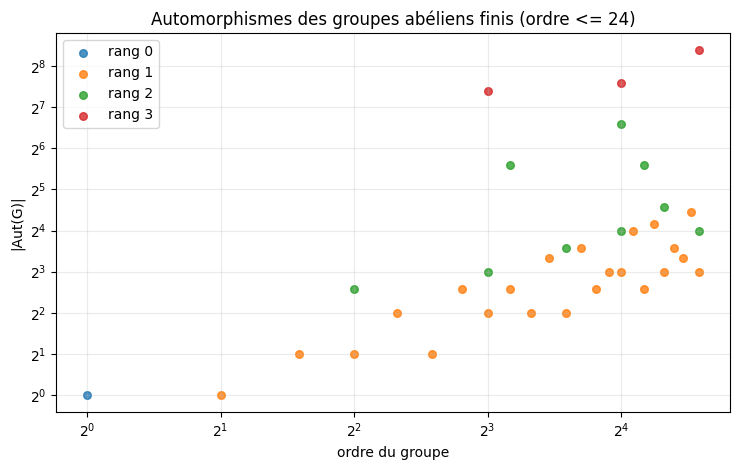

Groupes non figures (cout d'enumeration > 20000) :
  Z/2Z x Z/2Z x Z/2Z x Z/2Z : 65536 couples a examiner
Table par rang :
  rang 0 :   1 groupes, |Aut| de 1 a 1
  rang 1 :  23 groupes, |Aut| de 1 a 22
  rang 2 :   9 groupes, |Aut| de 6 a 96
  rang 3 :   3 groupes, |Aut| de 168 a 336


In [6]:
import matplotlib.pyplot as plt

ORDRE_MAX = 24
BUDGET = 20000
points = []
ignores = []
for N in range(1, ORDRE_MAX + 1):
    for A in groupes_abeliens(N):
        cout = A.ordre ** A.rang
        if cout > BUDGET:
            ignores.append((str(A), cout))
            continue
        points.append((A.ordre, aut_par_enumeration(A), len(A.invariants)))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for r in sorted({p[2] for p in points}):
    xs = [p[0] for p in points if p[2] == r]
    ys = [p[1] for p in points if p[2] == r]
    ax.scatter(xs, ys, s=30, alpha=0.8, label=f"rang {r}")
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.set_xlabel("ordre du groupe")
ax.set_ylabel("|Aut(G)|")
ax.set_title(f"Automorphismes des groupes abéliens finis (ordre <= {ORDRE_MAX})")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

if ignores:
    print("Groupes non figures (cout d'enumeration > %d) :" % BUDGET)
    for nom, cout in ignores:
        print(f"  {nom} : {cout} couples a examiner")
else:
    print("Aucun groupe ecarte : tous les groupes d'ordre <= %d ont ete figures." % ORDRE_MAX)

print("Table par rang :")
for r in sorted({p[2] for p in points}):
    lot = [p for p in points if p[2] == r]
    print(f"  rang {r} : {len(lot):>3} groupes, |Aut| de {min(p[1] for p in lot)} a {max(p[1] for p in lot)}")

### Lecture de la figure : l'automorphisme croît avec l'ordre, mais pas proportionnellement

Chaque point est un groupe abélien d'ordre au plus $24$, positionné par son ordre (axe
horizontal, logarithmique) et $|\mathrm{Aut}(G)|$ (axe vertical, logarithmique). Les couleurs
séparent les rangs.

Trois lectures :

- **La droite $y = x$ n'est pas une frontière** : selon la décomposition du groupe,
  $|\mathrm{Aut}(G)|$ est **en dessous** de $|G|$ pour les groupes cycliques
  ($\mathbb{Z}/12\mathbb{Z}$ : $4 < 12$) et **au-dessus** pour les groupes décomposés
  ($\mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2\mathbb{Z}$ : $6 > 4$ ;
  $\mathbb{Z}/2\mathbb{Z}^3$ : $168 > 8$). C'est la structure, pas l'ordre, qui décide.
- **Les rangs ne se mélangent pas** : à ordre égal, un groupe de rang $r$ et un groupe de
  rang $r+1$ apparaissent à des hauteurs différentes sur la figure. Deux groupes de même
  ordre mais de rangs différents sont donc déjà séparés par la seule verticale : c'est la
  même information que la table du §3, vue en continu.
- **La figure a une borne, et elle est nommée** : l'énumération des automorphismes teste
  $|G|^{\mathrm{rang}}$ couples, ce qui devient impraticable vite — le groupe
  $(\mathbb{Z}/2\mathbb{Z})^4$ a l'ordre $16$ et $16^4 = 65\,536$ couples à examiner. Le
  carnet ne figure donc que les groupes dont le coût d'énumération reste sous le budget
  affiché, et **les écarts sont nommés** dans la sortie : aucune troncature muette.

In [7]:
def groupe_unites(n):
    """Les classes inversibles modulo n (le groupe (Z/nZ)^x)."""
    return [a for a in range(n) if gcd(a, n) == 1]


def ordre_element(n, a):
    """Ordre multiplicatif de a modulo n (None si a n'est pas inversible)."""
    if gcd(a, n) != 1:
        return None
    k = 1
    x = a % n
    while x != 1:
        x = (x * a) % n
        k += 1
        if k > n:
            return None
    return k


def est_cyclique_unites(n):
    """(Z/nZ)^x est-il cyclique ? (il suffit qu'un élément ait l'ordre |(Z/nZ)^x|)."""
    unites = groupe_unites(n)
    return any(ordre_element(n, a) == len(unites) for a in unites)


def _log_p(x, p):
    """L'exposant e tel que p^e = x (x est une puissance de p)."""
    e = 0
    while x > 1:
        x //= p
        e += 1
    return e


def _est_p_puissance(o, p):
    """L'ordre o est-il une puissance du premier p ?"""
    if o == 1:
        return True
    facteurs = factorisation(o)
    return len(facteurs) == 1 and p in facteurs


def diviseurs_elementaires_unites(n):
    """Diviseurs élémentaires de (Z/nZ)^x, mesurés par le comptage des ordres.

    Pour chaque premier p de l'ordre du groupe, on isole le p-Sylow (les
    éléments dont l'ordre est une puissance de p) puis on compte c_k = nombre
    de ces éléments dont l'ordre divise p^k. Si S_k = log_p(c_k), alors
    S_k - S_{k-1} compte les facteurs cycliques d'exposant >= k, d'où le
    nombre de facteurs d'exposant exactement k.
    """
    unites = groupe_unites(n)
    total = len(unites)
    ordres = [ordre_element(n, a) for a in unites]
    resultat = {}
    for p in factorisation(total):
        sylow = [o for o in ordres if o is not None and _est_p_puissance(o, p)]
        if not sylow:
            resultat[p] = []
            continue
        c = {}
        k = 0
        while True:
            c[k] = sum(1 for o in sylow if o <= p ** k)
            if c[k] == len(sylow):
                break
            k += 1
            if k > 64:
                break
        S = {k: _log_p(c[k], p) for k in c}
        d = {k: S[k] - S.get(k - 1, 0) for k in S}
        facteurs = []
        for k in sorted(d):
            if d[k] - d.get(k + 1, 0) > 0:
                facteurs.append((k, d[k] - d.get(k + 1, 0)))
        resultat[p] = facteurs
    return resultat


def lisible_diviseurs(div):
    """Rendu lisible d'une décomposition en diviseurs élémentaires."""
    morceaux = []
    for p, facteurs in div.items():
        for e, multiplicity in facteurs:
            morceaux.extend([f"C_{{{p}^{{{e}}}}}"] * multiplicity)
    return " x ".join(morceaux) if morceaux else "trivial"


print(f"{'n':>5} {'|unites|':>9} {'cyclique':>9} {'exposant':>9}  structure mesuree")
for n in [2, 3, 4, 5, 7, 8, 9, 12, 16, 17, 25, 27, 32, 49]:
    unites = groupe_unites(n)
    exp = max(ordre_element(n, a) for a in unites)
    div = diviseurs_elementaires_unites(n)
    print(f"{n:>5} {len(unites):>9} {str(est_cyclique_unites(n)):>9} {exp:>9}  {lisible_diviseurs(div)}")

print()
print("Controle negatif : le groupe des unites n'est pas toujours cyclique")
for n in [8, 16, 32]:
    unites = groupe_unites(n)
    ordres = sorted(ordre_element(n, a) for a in unites)
    print(f"  n = {n:>2} : ordres des elements = {ordres}  -> cyclique ? {est_cyclique_unites(n)}")

    n  |unites|  cyclique  exposant  structure mesuree
    2         1      True         1  trivial
    3         2      True         2  C_{2^{1}}
    4         2      True         2  C_{2^{1}}
    5         4      True         4  C_{2^{2}}
    7         6      True         6  C_{2^{1}} x C_{3^{1}}
    8         4     False         2  C_{2^{1}} x C_{2^{1}}
    9         6      True         6  C_{2^{1}} x C_{3^{1}}
   12         4     False         2  C_{2^{1}} x C_{2^{1}}
   16         8     False         4  C_{2^{1}} x C_{2^{2}}
   17        16      True        16  C_{2^{4}}
   25        20      True        20  C_{2^{2}} x C_{5^{1}}
   27        18      True        18  C_{2^{1}} x C_{3^{2}}
   32        16     False         8  C_{2^{1}} x C_{2^{3}}
   49        42      True        42  C_{2^{1}} x C_{3^{1}} x C_{7^{1}}

Controle negatif : le groupe des unites n'est pas toujours cyclique
  n =  8 : ordres des elements = [1, 2, 2, 2]  -> cyclique ? False
  n = 16 : ordres des elements = 

### Lecture : la structure des unités se lit dans les ordres

Trois lectures :

1. **La colonne « structure mesurée » est le théorème de structure, vérifié par le
   comptage** : pour $n = 2^k$ avec $k \ge 3$ ($8$, $16$, $32$), elle affiche
   $\mathbb{Z}/2\mathbb{Z} \times \mathbb{Z}/2^{k-2}\mathbb{Z}$ ; pour $n = p^k$ premier
   impair ($9$, $25$, $27$), la composante $p$ est **un seul facteur cyclique**
   ($C_{3^2}$ pour $27$), et le groupe complet affiché est le produit des composantes $p$ —
   cyclique quand leurs ordres sont premiers entre eux, ce que la colonne « cyclique »
   confirme. Pour $n = 2$ et $n = 4$, les unités forment respectivement le groupe
   trivial et $C_2$.
2. **Le contrôle négatif fonctionne** : pour $n = 8$, les quatre unités ont pour ordres
   $1, 2, 2, 2$ ; le groupe n'est **pas** cyclique (l'exposant vaut $2 < 4 = |\text{unités}|$).
   La loi plausible « le groupe des unités modulo $n$ est cyclique » est donc **refutée**
   dès $n = 8$ — et le tableau la fait tomber, pas le texte.
3. **La mesure est un comptage, pas une application du théorème** : la structure affichée
   est reconstruite à partir du nombre d'éléments dont l'ordre divise $p^k$. Si le
   theorème de structure et ce comptage divergeaient, la sortie divergerait aussi.

## Exercices

Quatre exercices, dans l'esprit du chapitre : aucun ne demande de recopier un théorème,
tous demandent de le **confronter** à un calcul. Les stubs sont non bloquants : le carnet
s'exécute de bout en bout même si les exercices ne sont pas remplis.

### Exercice 1 — Recomposer la forme canonique

Écrire `forme_canonique(N)` qui renvoie la liste des suites de facteurs invariants
$(n_1 \mid n_2 \mid \dots \mid n_r)$ des groupes abéliens d'ordre $N$.

Indice : factoriser $N$, puis partitionner l'exposant de chaque premier ; combiner les
exposants en alignant les plus grands dans le **dernier** facteur, puis multiplier colonne
par colonne.

Vérification attendue une fois l'exercice fait : `forme_canonique(12)` doit contenir
`(12,)` et `(2, 6)`, et `len(forme_canonique(N)) == nombre_attendu(N)` pour tout $N \le 30$.

In [8]:
def forme_canonique(N):
    """Formes canoniques (facteurs invariants) des groupes abéliens d'ordre N.

    Indice : factoriser N, partitionner l'exposant de chaque premier, puis
    combiner les exposants en alignant les plus grands dans le dernier facteur.
    """
    # TODO etudiant : renvoyer la liste des suites d'invariants (n_1 | ... | n_r)
    resultat = None  # TODO etudiant
    return resultat


print("Exercice 1 : forme_canonique(12) a completer, renvoie", forme_canonique(12))

Exercice 1 : forme_canonique(12) a completer, renvoie None


### Exercice 2 — Compter les morphismes sans la formule

Écrire `nombre_morphismes(A, B)` qui renvoie le nombre de morphismes de $A$ dans $B$
**sans** utiliser `hom_formule`.

Indice : un morphisme est déterminé par l'image de chaque générateur ; l'image $x_i$ du
$i$-ième générateur doit vérifier $n_i \cdot x_i = 0$ dans $B$.

Vérification attendue : `nombre_morphismes(A, B) == hom_formule(A, B)` sur toutes les
paires du tableau du §3, et `nombre_morphismes(GroupeAbelien((4,)), GroupeAbelien((4,))) == 4`.

In [9]:
def nombre_morphismes(A, B):
    """Nombre de morphismes de A dans B, par énumération des images des générateurs.

    Indice : l'image x_i du i-ième générateur doit vérifier n_i * x_i = 0 dans B.
    """
    # TODO etudiant : enumerer les images des generateurs et ne garder que les valides
    resultat = None  # TODO etudiant
    return resultat


print("Exercice 2 : nombre_morphismes(Z/4Z, Z/4Z) a completer, renvoie",
      nombre_morphismes(GroupeAbelien((4,)), GroupeAbelien((4,))))

Exercice 2 : nombre_morphismes(Z/4Z, Z/4Z) a completer, renvoie None


### Exercice 3 — Reconnaître un groupe cyclique

Écrire `est_cyclique(A)` qui renvoie `True` si le groupe abélien $A$ possède un élément
d'ordre $|A|$.

Indice : l'ordre d'un élément s'obtient en itérant l'addition jusqu'à revenir au neutre.

Vérification attendue : `est_cyclique(GroupeAbelien((6,)))` est `True` (car $6 = 2 \times 3$
et $\gcd(2,3) = 1$), `est_cyclique(GroupeAbelien((2, 2)))` est `False`, et
`est_cyclique(GroupeAbelien((4,)))` est `True`.

In [10]:
def est_cyclique(A):
    """Le groupe A est-il cyclique ? (il existe un élément d'ordre |A|)"""
    # TODO etudiant : calculer les ordres des elements et conclure
    resultat = None  # TODO etudiant
    return resultat


print("Exercice 3 : est_cyclique(Z/6Z) a completer, renvoie", est_cyclique(GroupeAbelien((6,))))

Exercice 3 : est_cyclique(Z/6Z) a completer, renvoie None


### Exercice 4 — Mesurer la structure des unités

Écrire `structure_unites(n)` qui renvoie un triplet : le nombre d'unités, `True` si le
groupe des unités est cyclique, et la liste des diviseurs élémentaires (au sens du §5).

Indice : réutiliser `groupe_unites` et `ordre_element` ; la structure se déduit du nombre
d'éléments dont l'ordre divise $p^k$ pour chaque premier $p$.

Vérification attendue : `structure_unites(8)` doit rendre `(4, False, ...)` avec deux
facteurs d'exposant $1$ pour $p = 2$ ; `structure_unites(9)` doit rendre `(6, True, ...)`.

In [11]:
def structure_unites(n):
    """(Z/nZ)^x : taille, cyclique ou non, et diviseurs élémentaires.

    Indice : réutiliser groupe_unites et ordre_element ; la structure est
    déterminée par le nombre d'éléments dont l'ordre divise p^k.
    """
    # TODO etudiant : renvoyer (taille, cyclique, diviseurs elementaires)
    resultat = None  # TODO etudiant
    return resultat


print("Exercice 4 : structure_unites(8) a completer, renvoie", structure_unites(8))

Exercice 4 : structure_unites(8) a completer, renvoie None


## Conclusion et limites honnêtes

Ce que le carnet établit, et par quel moyen :

- la **forme canonique** des groupes abéliens finis est reconstruite par enumeration des
  diviseurs élémentaires, et le compte obtenu coïncide avec la formule $\prod_p p(a_p)$ —
  deux chemins indépendants ;
- **$|\mathrm{Hom}(A, B)|$** est mesuré par trois chemins (formule, images des générateurs,
  énumération de toutes les fonctions), tous concordants ;
- **$|\mathrm{Aut}(A)|$** est mesuré par énumération, et recoupé par le compte par
  déterminants pour $\mathrm{GL}(2, \mathbb{F}_2)$ ;
- la **structure de $(\mathbb{Z}/n\mathbb{Z})^\times$** est reconstruite par comptage des
  ordres, sans appliquer le théorème de structure.

Ce que le carnet **ne** fait pas, et qu'il faut dire :

1. **Aucune preuve** n'est produite ici : ce sont des vérifications sur des cas. Le passage
   au général est le rôle du versant formel (Mathlib), que ce carnet n'exécute pas — le
   carnet 08 montre comment la série articule les deux versants.
2. **La borne de calcul est réelle** : l'énumération de toutes les fonctions du §3 coûte
   $|B|^{|A|}$ — praticable jusqu'à $|A| = |B| = 6$, impraticable au-delà. Le §4 contourne
   la borne grâce à la description par générateurs, mais l'énumération des morphismes
   reste exponentielle en le rang.
3. **Le choix des groupes est orienté** : le carnet ne considère que des groupes
   **abéliens**, par construction de la machine (§1). Ce n'est pas un détail de taille —
   le plus petit groupe non abélien est d'ordre $6$ (le groupe symétrique $S_3$) — mais un
   choix de champ : le carnet 20 (Sylow) fournit le versant « groupe non abélien », et les
   deux se complètent.
4. **Une source n'est pas archivée** : le texte de référence usuel pour le chapitre de
   Serre consacré aux groupes abéliens ne figure pas encore dans le gisement
   bibliographique. La formulation employée ici est donc la version classique du
   théorème, énoncée sans attribution textuelle, plutôt qu'une citation vérifiable.

## Ressources

- La série : [README.md](README.md) — conventions, conventions de pull, grain `Grain:`.
- Carnets voisins : [20-sylow-p-sous-groupes.ipynb](20-sylow-p-sous-groupes.ipynb) (structure
  des groupes finis par leurs sous-groupes), [05-table-de-caracteres.ipynb](05-table-de-caracteres.ipynb)
  (spectres des groupes finis), [08-serre-dans-mathlib-Lean.ipynb](08-serre-dans-mathlib-Lean.ipynb)
  (versant des preuves).
- EPIC parent : #16334 (Serre 100).